## Oppgave 3e)

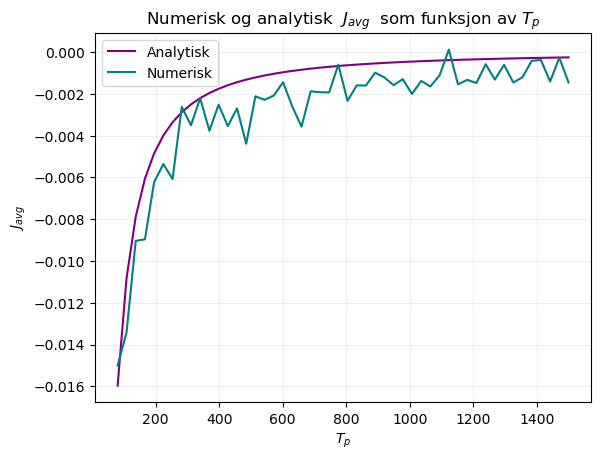

In [24]:
import numpy as np
import math
import matplotlib.pyplot as plt

alpha = 0.8
h = 1
N_x = 10
P = 2 * N_x      
N_p = 40 * N_x
Beta_k = 1000

T_p_vals = np.linspace(80, 1500, 50).astype(int)

rng = np.random.default_rng(0)

Beta_k_overflow = np.float128(Beta_k)  # Endre datatyp for å unngå Runtime error

def J_anal(T_p):

    sqr = np.sqrt(3 / T_p)
    a = ((alpha * N_x) / 2) * sqr
    b = (((1 - alpha) * N_x) / 2) * sqr
    return (N_x / (4 * T_p) ) * (math.erfc(a) - math.erfc(b))

def build_V1(alpha, N_x):
    peak = int(alpha * N_x)
    n = np.arange(N_x)

    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - n[right]) / max((N_x - peak), 1)

    return np.concatenate([V, V])

V1 = build_V1(alpha, N_x)
V2 = np.zeros(P)

min1 = np.argmin(V1[:N_x])
min2 = N_x + np.argmin(V1[N_x:])

x0 = np.array([min1] * (N_p // 2) + [min2] * (N_p // 2), dtype=int)

J_num =  np.zeros(len(T_p_vals))

for i, T_p in enumerate(T_p_vals):

    x = x0.copy()

    J_sum = 0
    n_steps = 2 * T_p

    for j in range(n_steps):
        
        if (j < T_p):
            V = V2
        else:
            V = V1
            
        V_l = V[(x - 1) % P]
        V_0 = V[x]
        V_r = V[(x + 1) % P]

        p_plus  = 1 / (1 + np.exp(-Beta_k_overflow*(V_l - V_r)) + np.exp(-Beta_k_overflow*(V_0 - V_r)))
        p_minus = 1 / (1 + np.exp(-Beta_k_overflow*(V_r - V_l)) + np.exp(-Beta_k_overflow*(V_0 - V_l)))
    
        r = rng.random(N_p)
    
        pos = np.zeros_like(x) # tomt array med posisjon 0
        pos[r < p_minus] = -1
        pos[r > 1 - p_plus] = +1

        n_plus  = np.sum(pos == 1) # teller hvor mange partikler som gikk til høyre
        n_minus = np.sum(pos == -1) # teller hvor mange partikler som gikk til venstre
        J_t = (n_plus - n_minus) / N_p  # current J[i]

        J_sum += J_t
        x = (x + pos) % P  # periodisk randbetingelse
        

    J_num[i] = J_sum / (2 * T_p)

J_analytical = np.zeros_like(T_p_vals, dtype=float)

for i, T_p in enumerate(T_p_vals):
    J_analytical[i] = J_anal(T_p)

plt.plot(T_p_vals, J_analytical, label="Analytisk", color = "purple")
plt.plot(T_p_vals, J_num, label="Numerisk", color = "teal")
plt.title("Numerisk og analytisk  $ J_{avg}$  som funksjon av $T_p$")
plt.grid(alpha = 0.2)
plt.xlabel("$T_p$")
plt.ylabel("$J_{avg}$")
plt.legend()
plt.show()

##### Kommentar til koden:
Plottet ovenfor viser en numerisk og analystisk løsning av $J_{avg}$ som funksjon av perioden $T_p$, med 20 ulike verdier av $T_p \in (80, 1500)$ og $\alpha = 0.8$. $J_{avg}$ er negativ både for den analytiske og numeriske løsningen for alle $T_p$. Dette er forventet ettersom $\alpha = 0.8$, altså er toppen av sagtannen forskjøvet mot høyre som resulterer i en strøm mot venstre. 
Lave verdier av $T_p$ gir størst absoluttverdi for $J_{avg}$. Dette kan forklares av at partiklene ikke rekker å spre seg i det flate potensiale, noe som kan lede til en sterk skjevhet når sagtannpotensialet bli påslått, og dermed en sterk strøm. Til tross for et større avvik for små verdier av $T_p$, følger begge kurvene samme trend. Ettersom verdien for $T_p$ øker, avtar $J_{avg}$ gradvis mot 0 for både den analytsike og numeriske løsningen. Slik som observert i oppgave 3b kan en økt periode lede til at partiklene rekker å spre seg nesten symmetrisk rundt minimum. Dermed vil bidragene kansellere ut hverandre og gir mindre netto forskyvning.

Den numeriske løsningen følger den analytiske i varierende grad. Dette kan undersøkes ved å se på absoluttverdien av differansen mellom kurvene.

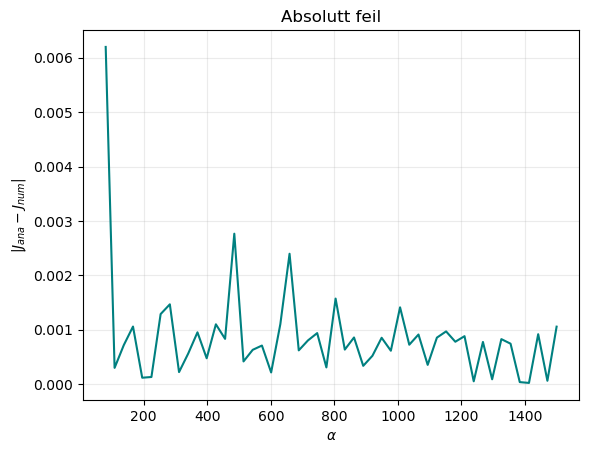

In [21]:
diff = J_analytical - J_num

abs_diff = np.abs(diff)

plt.figure()
plt.plot(T_p_vals, abs_diff, color = "teal")
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$ | J_{ana} - J_{num} | $")
plt.title("Absolutt feil")
plt.grid(alpha=0.25)
plt.show()

Som observert på det første plottet er det et merkbart avvik i $T_p = 0$. Partiklene får veldig lite tid på å spre seg, som gir tildelige bevegelser, og dermed et resultat som er tynget av støy for den numeriske løsningen. For den analutiske løsningen er det antatt at partiklene rekker å spre seg jevnt før sagtann-potensialet blir påslått som gir en kontinuerlig og fin kurve. Dette er en dårlig antakelse for små verdier av $T_p$, og resulterer da i et stort avvik mellom den numeriske og analytiske løsningen. Med økende $T_p$ får partiklene mer tid til å bevege seg, og støyen vil bli mindre dominerende, noe som gir mindre avvik mellom de to kurvene. 